# Практическая работа № 1 «Знакомство с библиотеками NumPy и Matplotlib»

**Выполнил:** Федотов Георгий Николаевич  
**Группа:** ИТ-23д  
**Вариант:** № 37

**Цель работы:** научиться создавать и преобразовывать массивы NumPy, выполнять вычисления без циклов и строить графики с помощью Matplotlib.

## Задания для самостоятельного решения

Во всех шести задачах номер варианта обозначен `v`. Для Федотова Георгия `v = 37`. Размеры массивов, число классов и величина шума вычисляются из этого числа. Там, где используются случайные значения, фиксируется `seed = 100 + v = 137`. Благодаря этому при повторном запуске получаются те же результаты.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

v = 37
seed = 100 + v
print(f'Вариант v = {v}, seed = {seed}')

Вариант v = 37, seed = 137


### Задача 1. Формы тензоров и работа с осями

**Что требуется.** Создать последовательность длины `12 + v`, представить одни и те же элементы как вектор, матрицу и трёхмерный массив. Затем найти первые элементы, транспонировать матрицу, посчитать суммы по двум осям и среднее тензора по последней оси.

Для варианта 37 длина равна **49**. Матрице `A` зададим форму `(1, 49)`: одна строка и 49 столбцов. Тогда результаты суммирования по двум осям будут иметь **разные формы**, как требует задание. Тензору `B` зададим форму `(1, 7, 7)`: один слой по семь строк и семь столбцов. `reshape` меняет представление данных, сохраняя порядок всех 49 чисел.

В матрице `axis=0` означает суммирование **вниз по строкам**, поэтому остаётся результат для каждого из 49 столбцов; `axis=1` означает суммирование **вдоль столбцов**, поэтому остаётся одна общая сумма для строки. Формы результатов `(49,)` и `(1,)`. В тензоре `axis=-1` указывает на последнюю ось длины 7; после усреднения она исчезает.


In [ ]:
# 12 + 37 = 49 последовательных целых чисел: от 0 до 48.
a = np.arange(12 + v)
A = a.reshape(1, 49)
B = a.reshape(1, 7, 7)

print('a =', a)
print('a: shape =', a.shape, 'ndim =', a.ndim)
print('A =\n', A)
print('A: shape =', A.shape, 'ndim =', A.ndim)
print('B =\n', B)
print('B: shape =', B.shape, 'ndim =', B.ndim)
print('Один и тот же первый элемент:', a[0], A[0, 0], B[0, 0, 0])

A_transposed = A.T
sum_axis_0 = A.sum(axis=0)  # одна сумма для каждого столбца
sum_axis_1 = A.sum(axis=1)  # одна сумма для каждой строки
mean_last = B.mean(axis=-1)

print('Транспонированная A =\n', A_transposed, 'форма:', A_transposed.shape)
print('Сумма по axis=0:', sum_axis_0, 'форма:', sum_axis_0.shape)
print('Сумма по axis=1:', sum_axis_1, 'форма:', sum_axis_1.shape)
print('Среднее B по последней оси =\n', mean_last, 'форма:', mean_last.shape)

assert a.size == 49 and A.shape == (1, 49) and B.shape == (1, 7, 7)
assert a[0] == A[0, 0] == B[0, 0, 0]
assert np.array_equal(sum_axis_0, A.sum(axis=0))
assert mean_last.shape == (1, 7)

a = [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48]
a: shape = (49,) ndim = 1
A =
 [[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
  24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
  48]]
A: shape = (1, 49) ndim = 2
B =
 [[[ 0  1  2  3  4  5  6]
  [ 7  8  9 10 11 12 13]
  [14 15 16 17 18 19 20]
  [21 22 23 24 25 26 27]
  [28 29 30 31 32 33 34]
  [35 36 37 38 39 40 41]
  [42 43 44 45 46 47 48]]]
B: shape = (1, 7, 7) ndim = 3
Один и тот же первый элемент: 0 0 0
Транспонированная A =
 [[ 0]
 [ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]
 [11]
 [12]
 [13]
 [14]
 [15]
 [16]
 [17]
 [18]
 [19]
 [20]
 [21]
 [22]
 [23]
 [24]
 [25]
 [26]
 [27]
 [28]
 [29]
 [30]
 [31]
 [32]
 [33]
 [34]
 [35]
 [36]
 [37]
 [38]
 [39]
 [40]
 [41]
 [42]
 [43]
 [44]
 [45]
 [46]
 [47]
 [48]] форма: (49, 1)
Сумма по axis=0: [ 0  1  2  3  4  5  6  7  8  9 10

**Вывод по задаче 1.** Числа от 0 до 48 остались теми же, изменился только способ их размещения: формы `(49,)`, `(1, 49)` и `(1, 7, 7)`. Первый элемент во всех трёх случаях равен 0, но записывается с разным количеством индексов. Транспонирование даёт матрицу формы `(49, 1)`. При суммировании направление `axis` определяет форму: `(49,)` по столбцам и `(1,)` по строкам. Среднее по последней оси `B` имеет форму `(1, 7)`.


### Задача 2. Матричные операции и проверка форм

**Что требуется.** Создать квадратную матрицу размера `(3 + v, 3 + v)` и вектор длины `3 + v`. Найти произведение матрицы на вектор, произведение транспонированной матрицы на исходную, скалярное произведение векторов и сумму диагонали.

При `v = 37` матрица имеет размер **40×40**, вектор содержит **40** чисел. Поэтому произведение `A @ b` тоже имеет длину 40, а `A.T @ A` является матрицей 40×40. Числа от 0 до 9 создаются генератором с `seed=137`. Полную матрицу `A.T @ A` выводить не нужно: задание просит её форму, а также сумму диагонали.


In [ ]:
rng = np.random.default_rng(seed)
n = 3 + v  # 40
A2 = rng.integers(0, 10, size=(n, n))
b = rng.integers(0, 10, size=n)

matrix_vector = A2 @ b
gram = A2.T @ A2
scalar_product = np.dot(b, matrix_vector)
diagonal_sum = np.trace(gram)

print('A.shape =', A2.shape, 'b.shape =', b.shape)
print('A @ b =', matrix_vector)
print('Форма A @ b:', matrix_vector.shape)
print('Форма A.T @ A:', gram.shape)
print('Скалярное произведение b и (A @ b):', scalar_product)
print('Сумма диагонали A.T @ A:', diagonal_sum)

assert matrix_vector.shape == (40,) and gram.shape == (40, 40)
assert diagonal_sum == np.sum(A2 * A2)

A.shape = (40, 40) b.shape = (40,)
A @ b = [ 936  925 1117  849  945  736  846 1047  744 1021 1073  834  775  822
  892 1018 1039  944  850  862  920  823  919  869 1011 1071  824  858
  920 1004 1040  888  948  940  863  941  941 1052 1043  939]
Форма A @ b: (40,)
Форма A.T @ A: (40, 40)
Скалярное произведение b и (A @ b): 190145
Сумма диагонали A.T @ A: 46082


**Вывод по задаче 2.** Матричное умножение `@` учитывает расположение строк и столбцов: матрица 40×40, умноженная на вектор длины 40, даёт вектор длины 40. Произведение `A.T @ A` снова имеет форму 40×40. Скалярное произведение и сумма диагонали дают по одному числу. Равенство суммы диагонали $A^T A$ сумме квадратов всех элементов $A$ служит дополнительной проверкой расчёта.


### Задача 3. Векторизация: значения функции на сетке

**Что требуется.** Построить `N = 200 + 10·v` точек на отрезке `[-10, 10]`, вычислить значения функции сразу для всего массива, найти минимум, максимум, среднее, число точек с заданным условием и точку максимума $|y|$.

При `v=37` число точек **N=570**. В условии не дана отдельная формула именно для варианта 37, поэтому по предложенному в методичке типу задаём $f(x)=\sin(x)+\frac{v}{100}x^2=\sin(x)+0{,}37x^2$. Синусоидальная составляющая колеблется, а квадрат при удалении от нуля растёт. Для булевой маски возьмём условие $y>v/10=3{,}7$. Каждая операция применяется ко всему массиву без цикла.


In [ ]:
N = 200 + 10 * v
x3 = np.linspace(-10, 10, N)
y3 = np.sin(x3) + (v / 100) * x3**2

mask = y3 > v / 10
max_abs_index = np.argmax(np.abs(y3))

print('x.shape =', x3.shape, 'y.shape =', y3.shape)
print(f'Минимум y = {y3.min():.4f}; максимум y = {y3.max():.4f}')
print(f'Среднее y = {y3.mean():.4f}')
print(f'Число точек, где y > {v/10:.1f}: {np.count_nonzero(mask)}')
print(f'Максимум |y|: индекс {max_abs_index}, x = {x3[max_abs_index]:.4f}, y = {y3[max_abs_index]:.4f}')

assert x3.shape == y3.shape == (570,)
assert max_abs_index == np.abs(y3).argmax()

x.shape = (570,) y.shape = (570,)
Минимум y = -0.4842; максимум y = 37.5440
Среднее y = 12.3767
Число точек, где y > 3.7: 390
Максимум |y|: индекс 0, x = -10.0000, y = 37.5440


**Вывод по задаче 3.** Получены два массива одинаковой длины: один хранит координаты $x$, другой — соответствующие значения функции. Булева маска отмечает все точки выше порога 3,7, а `np.count_nonzero` считает их. `np.argmax(np.abs(y3))` возвращает **индекс** максимума модуля, по которому затем находятся сами $x$ и $y$. Цикл для вычисления 570 значений не понадобился.


### Задача 4. Склейка массивов и формы

**Что требуется.** Создать две матрицы одинаковой формы `(3, 4 + v)` и объединить их по столбцам и по строкам.

При варианте 37 обе матрицы имеют форму **3×41**. Склейка `hstack` располагает вторую справа от первой: получится 3×82. Склейка `vstack` располагает вторую под первой: получится 6×41. Значения заполнены случайными целыми числами с тем же фиксированным seed.


In [ ]:
rng = np.random.default_rng(seed)
A4 = rng.integers(0, 10, size=(3, 4 + v))
B4 = rng.integers(0, 10, size=(3, 4 + v))

by_columns = np.hstack((A4, B4))
by_rows = np.vstack((A4, B4))

print('A.shape =', A4.shape, 'B.shape =', B4.shape)
print('По столбцам (A слева, B справа):\n', by_columns)
print('Форма:', by_columns.shape)
print('По строкам (A сверху, B снизу):\n', by_rows)
print('Форма:', by_rows.shape)

assert by_columns.shape == (3, 82)
assert by_rows.shape == (6, 41)
assert np.array_equal(by_columns[:, :41], A4)
assert np.array_equal(by_rows[3:, :], B4)

A.shape = (3, 41) B.shape = (3, 41)
По столбцам (A слева, B справа):
 [[4 8 2 2 8 4 1 6 5 4 3 4 2 5 2 3 1 0 9 4 9 8 9 8 4 7 2 5 9 1 4 4 0 6 7 2
  5 9 2 5 9 8 2 9 2 7 3 6 6 8 7 0 5 6 1 5 0 6 0 7 7 0 3 5 6 7 3 5 1 0 4 0
  6 0 7 0 9 3 9 2 3 3]
 [7 6 8 5 4 4 5 4 2 7 7 9 0 7 0 2 9 3 0 6 1 6 4 3 4 7 9 0 7 0 0 5 0 9 9 5
  0 6 2 6 2 0 6 8 7 8 5 3 8 6 6 8 5 5 4 5 8 7 1 3 0 5 8 6 7 0 6 8 8 2 4 2
  5 7 6 4 0 6 1 3 1 0]
 [9 5 8 8 9 9 1 4 4 0 7 3 4 8 9 5 9 0 1 2 9 3 9 5 2 5 6 0 4 4 4 1 8 1 6 0
  9 8 6 3 5 1 1 0 2 3 3 3 0 2 0 1 5 6 7 1 5 9 2 8 4 7 1 1 8 9 9 1 3 6 0 8
  1 7 6 3 7 8 1 3 0 1]]
Форма: (3, 82)
По строкам (A сверху, B снизу):
 [[4 8 2 2 8 4 1 6 5 4 3 4 2 5 2 3 1 0 9 4 9 8 9 8 4 7 2 5 9 1 4 4 0 6 7 2
  5 9 2 5 9]
 [7 6 8 5 4 4 5 4 2 7 7 9 0 7 0 2 9 3 0 6 1 6 4 3 4 7 9 0 7 0 0 5 0 9 9 5
  0 6 2 6 2]
 [9 5 8 8 9 9 1 4 4 0 7 3 4 8 9 5 9 0 1 2 9 3 9 5 2 5 6 0 4 4 4 1 8 1 6 0
  9 8 6 3 5]
 [8 2 9 2 7 3 6 6 8 7 0 5 6 1 5 0 6 0 7 7 0 3 5 6 7 3 5 1 0 4 0 6 0 7 0 9
  3 9 2 3 3]
 [0 6 8 7 8 5 3 8 6 

**Вывод по задаче 4.** При склейке по столбцам число строк осталось равным 3, а число столбцов выросло с 41 до 82. При склейке по строкам столбцов осталось 41, а строк стало 6. Исходные значения сохранены: изменилось только размещение двух матриц относительно друг друга.


### Задача 5. Столбчатая диаграмма частот классов

**Что требуется.** Сгенерировать `N = 200 + 10·v` меток, определить `K = 3 + (v % 4)` классов, посчитать частоту каждого и построить столбчатую диаграмму.

Для варианта 37 получаем **570 меток** и **4 класса**, потому что остаток от деления 37 на 4 равен 1. Номера классов: 0, 1, 2, 3. `np.bincount` за один вызов подсчитывает, сколько раз встретилась каждая целая метка. Сумма высот всех столбцов должна равняться 570.


N = 570 K = 4
Частоты классов 0..3: [136 152 150 132]
Сумма частот: 570


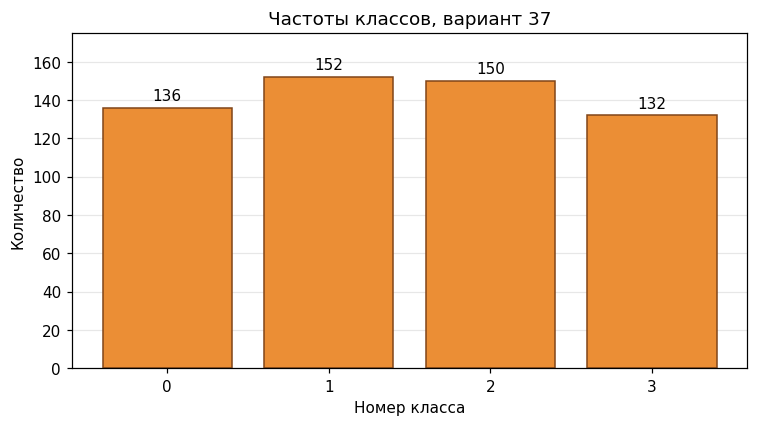

In [ ]:
rng = np.random.default_rng(seed)
N = 200 + 10 * v
K = 3 + (v % 4)
labels5 = rng.integers(0, K, size=N)
counts5 = np.bincount(labels5, minlength=K)

print('N =', N, 'K =', K)
print('Частоты классов 0..3:', counts5)
print('Сумма частот:', counts5.sum())

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(np.arange(K), counts5, color='#eb8e35', edgecolor='#814519')
ax.bar_label(bars, padding=3)
ax.set(title='Частоты классов, вариант 37', xlabel='Номер класса', ylabel='Количество')
ax.set_xticks(np.arange(K))
ax.set_ylim(0, counts5.max() * 1.15)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

assert counts5.size == K and counts5.sum() == N

**Вывод по задаче 5.** Высота каждого столбца показывает число меток соответствующего класса. Над столбцами написаны точные частоты, а горизонтальная сетка помогает их сравнивать. Сумма четырёх частот равна 570, поэтому все сгенерированные метки учтены. Различия высот возникли из-за случайного выбора меток; они не показывают качество модели.


### Задача 6. Визуализация ошибки (loss) и оформление графиков

**Что требуется.** Создать 570 точек на `[-5, 5]`, принять $\sin(x)$ за истинную функцию, добавить случайный шум к «предсказанию», рассчитать ошибку и её квадрат. Слева показать две линии на одном графике, справа — квадрат ошибки в каждой точке. Среднюю квадратичную ошибку написать в заголовке второго графика.

Для варианта 37 стандартное отклонение шума по образцу методички $\sigma=0{,}10+0{,}01v=0{,}47$. Формулы: $e_i=y_{pred,i}-y_{true,i}$, $loss_i=e_i^2$, $loss_{mean}=\frac{1}{N}\sum_{i=1}^{N}loss_i$. На первом графике шум видно как отклонение оранжевой линии от синуса; на втором высокий столбик линии означает большую ошибку в соответствующей точке. Это учебная имитация «предсказания», без обучения нейронной сети.


Вариант v = 37; N = 570; sigma = 0.47
Средний loss = 0.2303


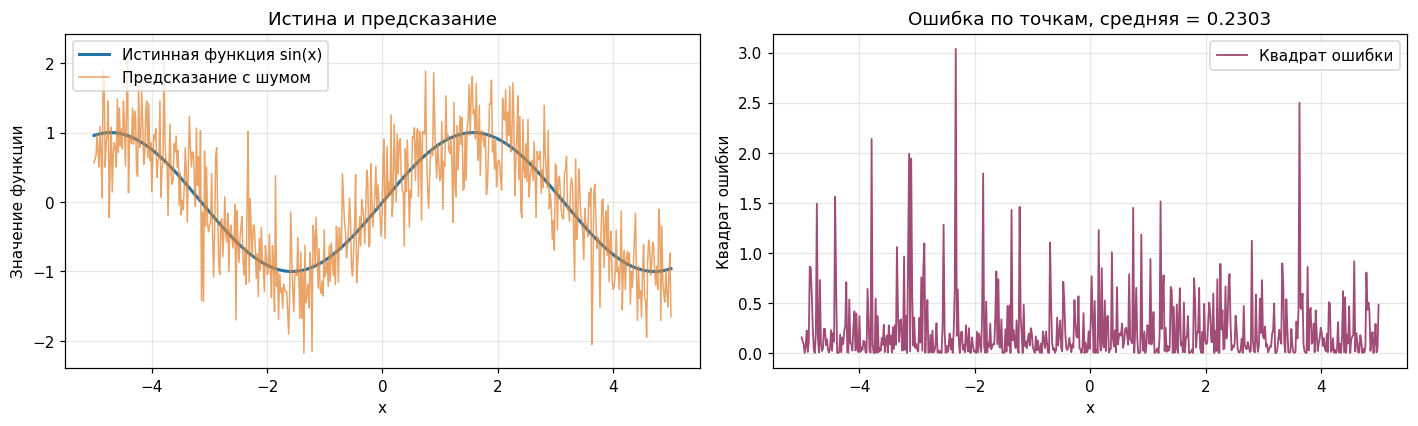

In [ ]:
rng = np.random.default_rng(seed)
N = 200 + 10 * v
x6 = np.linspace(-5, 5, N)
y_true = np.sin(x6)
sigma = 0.10 + 0.01 * v
noise = rng.normal(loc=0.0, scale=sigma, size=N)
y_pred = y_true + noise

error = y_pred - y_true
loss_point = error**2
loss_mean = np.mean(loss_point)

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].plot(x6, y_true, label='Истинная функция sin(x)', linewidth=2, color='#2374a6')
axs[0].plot(x6, y_pred, label='Предсказание с шумом', linewidth=1, alpha=.75, color='#e48635')
axs[0].set(title='Истина и предсказание', xlabel='x', ylabel='Значение функции')
axs[0].grid(alpha=.3)
axs[0].legend()

axs[1].plot(x6, loss_point, label='Квадрат ошибки', color='#a14b77', linewidth=1.2)
axs[1].set(title=f'Ошибка по точкам, средняя = {loss_mean:.4f}', xlabel='x', ylabel='Квадрат ошибки')
axs[1].grid(alpha=.3)
axs[1].legend()
fig.tight_layout()
plt.show()

print(f'Вариант v = {v}; N = {N}; sigma = {sigma:.2f}')
print(f'Средний loss = {loss_mean:.4f}')
assert x6.shape == y_true.shape == y_pred.shape == loss_point.shape == (570,)
assert np.all(loss_point >= 0) and np.isclose(loss_mean, np.mean(error**2))

**Вывод по задаче 6.** На левом графике истинный синус остаётся гладким, а «предсказание» колеблется вокруг него из-за добавленного шума. Справа видна ошибка в каждой точке: возведение разности в квадрат делает все значения неотрицательными и сильнее выделяет большие отклонения. Одно число `loss_mean` даёт средний уровень квадрата ошибки для всех 570 точек; его фактическое значение напечатано под графиком и в заголовке справа. При повторном запуске оно совпадает благодаря фиксированному seed.

### Общий вывод

Я создал массивы нескольких размерностей и проверил, как их форма влияет на индексацию и вычисления. Матричные операции, обработка 570 точек и подсчёт частот выполнены средствами NumPy без циклов `for`. С помощью Matplotlib построены диаграмма частот и два графика для сравнения истинных значений с шумным результатом. Номер варианта 37 учтён в размерах данных, числе классов и уровне шума, а фиксированный генератор обеспечивает воспроизводимость результатов.
